In [1]:
import os
import numpy as np
from datetime import datetime
import tf2onnx
import keras
from keras.metrics import BinaryAccuracy, SparseCategoricalAccuracy
from keras.models import load_model
from tqdm import tqdm  # For dynamic progress updates
from cnn.model import ResNetClassifier
from utils import load_features_from_hdf5
from data_preprocessing import (
    extract_and_concatenate_with_grouping,
    extract_and_concatenate_with_grouping_channel,
    extract_and_concatenate_with_grouping_tdl_cdl,
    extract_and_concatenate_with_grouping_channel_tdl_cdl,
)

from cnn.layers import (
    downsample,
    upsample,
    integrate_oper_upsample,
    integrate_oper_downsample,
    EncoderMiniBlock,
    DecoderMiniBlock,
    Oper2D,
    Oper2DTranspose,
)
from cnn.model import ResNetClassifier
from cnn.module import ResNet
from evaluation import print_metrics, print_metrics_multiclass
from visualization import (
    plot_confusion_matrix,
    plot_confusion_matrix_multiclass,
    plot_roc_curve,
    plot_roc_curve_multiclass,
)
import onnxruntime as ort  # ONNX Runtime for inference
if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 2  # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
    print(f"Using GPU {gpu_num}")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel("ERROR")

2025-03-31 21:40:03.887869: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1743446403.907879  805196 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1743446403.914171  805196 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1743446403.930200  805196 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1743446403.930218  805196 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1743446403.930221  805196 computation_placer.cc:177] computation placer alr

Using GPU 2


In [2]:
# Load features from HDF5 files

mimo_los_test = load_features_from_hdf5('dataset/dataset_sionna_mimo_los_test.h5')
mimo_los_train = load_features_from_hdf5('dataset/dataset_sionna_mimo_los.h5')
mimo_nlos_test = load_features_from_hdf5('dataset/dataset_sionna_mimo_nlos_test.h5')
mimo_nlos_train = load_features_from_hdf5('dataset/dataset_sionna_mimo_nlos.h5')
siso_los_test = load_features_from_hdf5('dataset/dataset_sionna_siso_los_test.h5')
siso_los_train = load_features_from_hdf5('dataset/dataset_sionna_siso_los.h5')
siso_nlos_test = load_features_from_hdf5('dataset/dataset_sionna_siso_nlos_test.h5')
siso_nlos_train = load_features_from_hdf5('dataset/dataset_sionna_siso_nlos.h5')
tdl_cdl_test = load_features_from_hdf5('dataset/dataset_tdl_cdl_test.h5')
tdl_cdl_train = load_features_from_hdf5('dataset/dataset_tdl_cdl.h5')
tdl_cdl_test = load_features_from_hdf5('dataset/dataset_tdl_cdl_test.h5')
tdl_cdl_train = load_features_from_hdf5('dataset/dataset_tdl_cdl.h5')
# 
# Extract and concatenate for MIMO datasets
train_mimo_los, train_mimo_los_labels = extract_and_concatenate_with_grouping(mimo_los_train)
train_mimo_nlos, train_mimo_nlos_labels = extract_and_concatenate_with_grouping(mimo_nlos_train)
train_siso_los, train_siso_los_labels = extract_and_concatenate_with_grouping(siso_los_train)
train_siso_nlos, train_siso_nlos_labels = extract_and_concatenate_with_grouping(siso_nlos_train)

test_mimo_los, test_mimo_los_labels = extract_and_concatenate_with_grouping(mimo_los_test)
test_mimo_nlos, test_mimo_nlos_labels = extract_and_concatenate_with_grouping(mimo_nlos_test)
test_siso_los, test_siso_los_labels = extract_and_concatenate_with_grouping(siso_los_test)
test_siso_nlos, test_siso_nlos_labels = extract_and_concatenate_with_grouping(siso_nlos_test)
train_tdls, train_cdls, train_tdls_labels, train_cdls_labels = extract_and_concatenate_with_grouping_tdl_cdl(tdl_cdl_train)
test_tdls, test_cdls, test_tdls_labels, test_cdls_labels = extract_and_concatenate_with_grouping_tdl_cdl(tdl_cdl_test)

train_mimo_los_channel, train_mimo_los_labels_channel = extract_and_concatenate_with_grouping_channel(mimo_los_train)
train_mimo_nlos_channel, train_mimo_nlos_labels_channel = extract_and_concatenate_with_grouping_channel(mimo_nlos_train)
train_siso_los_channel, train_siso_los_labels_channel = extract_and_concatenate_with_grouping_channel(siso_los_train)
train_siso_nlos_channel, train_siso_nlos_labels_channel = extract_and_concatenate_with_grouping_channel(siso_nlos_train)
test_mimo_los_channel, test_mimo_los_labels_channel = extract_and_concatenate_with_grouping_channel(mimo_los_test)
test_mimo_nlos_channel, test_mimo_nlos_labels_channel = extract_and_concatenate_with_grouping_channel(mimo_nlos_test)
test_siso_los_channel, test_siso_los_labels_channel = extract_and_concatenate_with_grouping_channel(siso_los_test)
test_siso_nlos_channel, test_siso_nlos_labels_channel = extract_and_concatenate_with_grouping_channel(siso_nlos_test)

# Extract and concatenate for MIMO datasets with channel dimension
train_tdls_channel, train_cdls_channel, label_tdl, label_cdl = extract_and_concatenate_with_grouping_channel_tdl_cdl(tdl_cdl_train)
test_tdls_channel, test_cdls_channel, test_label_tdl, test_label_cdl = extract_and_concatenate_with_grouping_channel_tdl_cdl(tdl_cdl_test)



In [3]:
print("train_tdls shape:", train_tdls.shape)
print("train_cdls shape:", train_cdls.shape)
print("train_tdls_channel shape:", train_tdls_channel.shape)
print("train_cdls_channel shape:", train_cdls_channel.shape)
print("train_tdls_labels shape:", train_tdls_labels.shape)
print("train_cdls_labels shape:", train_cdls_labels.shape)
print("test_tdls shape:", test_tdls.shape)
print("test_cdls shape:", test_cdls.shape)
print("test_tdls_channel shape:", test_tdls_channel.shape)
print("test_cdls_channel shape:", test_cdls_channel.shape)
print("test_tdls_labels shape:", test_tdls_labels.shape)
print("test_cdls_labels shape:", test_cdls_labels.shape)

train_tdls shape: (10000, 1, 1, 4, 14, 192)
train_cdls shape: (10000, 1, 1, 4, 14, 192)
train_tdls_channel shape: (10000, 1, 1, 4, 14, 192)
train_cdls_channel shape: (10000, 1, 1, 4, 14, 192)
train_tdls_labels shape: (10000,)
train_cdls_labels shape: (10000,)
test_tdls shape: (5000, 1, 1, 4, 14, 192)
test_cdls shape: (5000, 1, 1, 4, 14, 192)
test_tdls_channel shape: (5000, 1, 1, 4, 14, 192)
test_cdls_channel shape: (5000, 1, 1, 4, 14, 192)
test_tdls_labels shape: (5000,)
test_cdls_labels shape: (5000,)


In [4]:
# Combine dimensions for MIMO data (e.g., 1 and 2 -> 1 * 2 = 2)
train_mimo_los = train_mimo_los.reshape(train_mimo_los.shape[0], train_mimo_los.shape[1], train_mimo_los.shape[2] * train_mimo_los.shape[3], train_mimo_los.shape[4], train_mimo_los.shape[5])
train_mimo_nlos = train_mimo_nlos.reshape(train_mimo_nlos.shape[0], train_mimo_nlos.shape[1], train_mimo_nlos.shape[2] * train_mimo_nlos.shape[3], train_mimo_nlos.shape[4], train_mimo_nlos.shape[5])
test_mimo_los = test_mimo_los.reshape(test_mimo_los.shape[0], test_mimo_los.shape[1], test_mimo_los.shape[2] * test_mimo_los.shape[3], test_mimo_los.shape[4], test_mimo_los.shape[5])
test_mimo_nlos = test_mimo_nlos.reshape(test_mimo_nlos.shape[0], test_mimo_nlos.shape[1], test_mimo_nlos.shape[2] * test_mimo_nlos.shape[3], test_mimo_nlos.shape[4], test_mimo_nlos.shape[5])
print("train_mimo_los shape after reshape:", train_mimo_los.shape)
print("train_mimo_nlos shape after reshape:", train_mimo_nlos.shape)
print("test_mimo_los shape after reshape:", test_mimo_los.shape)
print("test_mimo_nlos shape after reshape:", test_mimo_nlos.shape)

train_mimo_los_channel = train_mimo_los_channel.reshape(train_mimo_los_channel.shape[0], train_mimo_los_channel.shape[1], train_mimo_los_channel.shape[2] * train_mimo_los_channel.shape[3], train_mimo_los_channel.shape[4], train_mimo_los_channel.shape[5])
train_mimo_nlos_channel = train_mimo_nlos_channel.reshape(train_mimo_nlos_channel.shape[0], train_mimo_nlos_channel.shape[1], train_mimo_nlos_channel.shape[2] * train_mimo_nlos_channel.shape[3], train_mimo_nlos_channel.shape[4], train_mimo_nlos_channel.shape[5])
test_mimo_los_channel = test_mimo_los_channel.reshape(test_mimo_los_channel.shape[0], test_mimo_los_channel.shape[1], test_mimo_los_channel.shape[2] * test_mimo_los_channel.shape[3], test_mimo_los_channel.shape[4], test_mimo_los_channel.shape[5])
test_mimo_nlos_channel = test_mimo_nlos_channel.reshape(test_mimo_nlos_channel.shape[0], test_mimo_nlos_channel.shape[1], test_mimo_nlos_channel.shape[2] * test_mimo_nlos_channel.shape[3], test_mimo_nlos_channel.shape[4], test_mimo_nlos_channel.shape[5])
print("train_mimo_los_channel shape after reshape:", train_mimo_los_channel.shape)
print("train_mimo_nlos_channel shape after reshape:", train_mimo_nlos_channel.shape)
print("test_mimo_los_channel shape after reshape:", test_mimo_los_channel.shape)
print("test_mimo_nlos_channel shape after reshape:", test_mimo_nlos_channel.shape)

# Combine dimensions for SISO data (e.g., 1 and 2 -> 1 * 2 = 2)
train_siso_los = train_siso_los.reshape(train_siso_los.shape[0], train_siso_los.shape[1], train_siso_los.shape[2] * train_siso_los.shape[3], train_siso_los.shape[4], train_siso_los.shape[5])
train_siso_nlos = train_siso_nlos.reshape(train_siso_nlos.shape[0], train_siso_nlos.shape[1], train_siso_nlos.shape[2] * train_siso_nlos.shape[3], train_siso_nlos.shape[4], train_siso_nlos.shape[5])
test_siso_los = test_siso_los.reshape(test_siso_los.shape[0], test_siso_los.shape[1], test_siso_los.shape[2] * test_siso_los.shape[3], test_siso_los.shape[4], test_siso_los.shape[5])
test_siso_nlos = test_siso_nlos.reshape(test_siso_nlos.shape[0], test_siso_nlos.shape[1], test_siso_nlos.shape[2] * test_siso_nlos.shape[3], test_siso_nlos.shape[4], test_siso_nlos.shape[5])
print("train_siso_los shape after reshape:", train_siso_los.shape)
print("train_siso_nlos shape after reshape:", train_siso_nlos.shape)
print("test_siso_los shape after reshape:", test_siso_los.shape)
print("test_siso_nlos shape after reshape:", test_siso_nlos.shape)

train_siso_los_channel = train_siso_los_channel.reshape(train_siso_los_channel.shape[0], train_siso_los_channel.shape[1], train_siso_los_channel.shape[2] * train_siso_los_channel.shape[3], train_siso_los_channel.shape[4], train_siso_los_channel.shape[5])
train_siso_nlos_channel = train_siso_nlos_channel.reshape(train_siso_nlos_channel.shape[0], train_siso_nlos_channel.shape[1], train_siso_nlos_channel.shape[2] * train_siso_nlos_channel.shape[3], train_siso_nlos_channel.shape[4], train_siso_nlos_channel.shape[5])
test_siso_los_channel = test_siso_los_channel.reshape(test_siso_los_channel.shape[0], test_siso_los_channel.shape[1], test_siso_los_channel.shape[2] * test_siso_los_channel.shape[3], test_siso_los_channel.shape[4], test_siso_los_channel.shape[5])
test_siso_nlos_channel = test_siso_nlos_channel.reshape(test_siso_nlos_channel.shape[0], test_siso_nlos_channel.shape[1], test_siso_nlos_channel.shape[2] * test_siso_nlos_channel.shape[3], test_siso_nlos_channel.shape[4], test_siso_nlos_channel.shape[5])
print("train_siso_los_channel shape after reshape:", train_siso_los_channel.shape)
print("train_siso_nlos_channel shape after reshape:", train_siso_nlos_channel.shape)
print("test_siso_los_channel shape after reshape:", test_siso_los_channel.shape)
print("test_siso_nlos_channel shape after reshape:", test_siso_nlos_channel.shape)

# Combine dimensions for TDL/CDL data (e.g., 1 and 1 -> 1 * 1 = 1, effectively removing them)
train_tdls = train_tdls.reshape(train_tdls.shape[0], train_tdls.shape[1], train_tdls.shape[2] * train_tdls.shape[3], train_tdls.shape[4], train_tdls.shape[5])
train_cdls = train_cdls.reshape(train_cdls.shape[0], train_cdls.shape[1], train_cdls.shape[2] * train_cdls.shape[3], train_cdls.shape[4], train_cdls.shape[5])
print("train_tdls shape after reshape:", train_tdls.shape)
print("train_cdls shape after reshape:", train_cdls.shape)

train_tdls_channel = train_tdls_channel.reshape(train_tdls_channel.shape[0], train_tdls_channel.shape[1], train_tdls_channel.shape[2] * train_tdls_channel.shape[3], train_tdls_channel.shape[4], train_tdls_channel.shape[5])
train_cdls_channel = train_cdls_channel.reshape(train_cdls_channel.shape[0], train_cdls_channel.shape[1], train_cdls_channel.shape[2] * train_cdls_channel.shape[3], train_cdls_channel.shape[4], train_cdls_channel.shape[5])
print("train_tdls_channel shape after reshape:", train_tdls_channel.shape)
print("train_cdls_channel shape after reshape:", train_cdls_channel.shape)    

test_cdls = test_cdls.reshape(test_cdls.shape[0], test_cdls.shape[1], test_cdls.shape[2] * test_cdls.shape[3], test_cdls.shape[4], test_cdls.shape[5])
test_tdls = test_tdls.reshape(test_tdls.shape[0], test_tdls.shape[1], test_tdls.shape[2] * test_tdls.shape[3], test_tdls.shape[4], test_tdls.shape[5])
print("test_tdls shape after reshape:", test_tdls.shape)
print("test_cdls shape after reshape:", test_cdls.shape)
test_tdls_channel = test_tdls_channel.reshape(test_tdls_channel.shape[0], test_tdls_channel.shape[1], test_tdls_channel.shape[2] * test_tdls_channel.shape[3], test_tdls_channel.shape[4], test_tdls_channel.shape[5])
test_cdls_channel = test_cdls_channel.reshape(test_cdls_channel.shape[0], test_cdls_channel.shape[1], test_cdls_channel.shape[2] * test_cdls_channel.shape[3], test_cdls_channel.shape[4], test_cdls_channel.shape[5])
print("test_tdls_channel shape after reshape:", test_tdls_channel.shape)
print("test_cdls_channel shape after reshape:", test_cdls_channel.shape)


train_mimo_los shape after reshape: (2000, 1, 4, 14, 192)
train_mimo_nlos shape after reshape: (2000, 1, 4, 14, 192)
test_mimo_los shape after reshape: (1000, 1, 4, 14, 192)
test_mimo_nlos shape after reshape: (1000, 1, 4, 14, 192)
train_mimo_los_channel shape after reshape: (2000, 1, 4, 14, 192)
train_mimo_nlos_channel shape after reshape: (2000, 1, 4, 14, 192)
test_mimo_los_channel shape after reshape: (1000, 1, 4, 14, 192)
test_mimo_nlos_channel shape after reshape: (1000, 1, 4, 14, 192)
train_siso_los shape after reshape: (2000, 1, 4, 14, 192)
train_siso_nlos shape after reshape: (2000, 1, 4, 14, 192)
test_siso_los shape after reshape: (1000, 1, 4, 14, 192)
test_siso_nlos shape after reshape: (1000, 1, 4, 14, 192)
train_siso_los_channel shape after reshape: (2000, 1, 4, 14, 192)
train_siso_nlos_channel shape after reshape: (2000, 1, 4, 14, 192)
test_siso_los_channel shape after reshape: (1000, 1, 4, 14, 192)
test_siso_nlos_channel shape after reshape: (1000, 1, 4, 14, 192)
train_td

In [5]:
train_data = np.concatenate((train_tdls, train_cdls), axis=0)
train_data_labels = np.concatenate((train_tdls_labels, train_cdls_labels), axis=0)
valid_data = np.concatenate((train_mimo_los, train_mimo_nlos, train_siso_los, train_siso_nlos), axis=0)
valid_data_labels = np.concatenate((train_mimo_los_labels, train_mimo_nlos_labels, train_siso_los_labels, train_siso_nlos_labels), axis=0)
test_data = np.concatenate((test_tdls, test_cdls), axis=0)
test_data_labels = np.concatenate((test_tdls_labels, test_cdls_labels), axis=0)
print("train_data shape:", train_data.shape)
print("train_labels shape:", train_data_labels.shape)
print("valid_data shape:", valid_data.shape)
print("valid_labels shape:", valid_data_labels.shape)
print("test_data shape:", test_data.shape)
print("test_labels shape:", test_data_labels.shape)

train_data_channel = np.concatenate((train_tdls_channel, train_cdls_channel), axis=0)
train_data_channel_labels = np.concatenate((label_tdl, label_cdl), axis=0)
valid_data_channel = np.concatenate((train_mimo_los_channel, train_mimo_nlos_channel, train_siso_los_channel, train_siso_nlos_channel), axis=0)
valid_data_channel_labels = np.concatenate((train_mimo_los_labels_channel, train_mimo_nlos_labels_channel, train_siso_los_labels_channel, train_siso_nlos_labels_channel), axis=0)
test_data_channel = np.concatenate((test_tdls_channel, test_cdls_channel), axis=0)
test_data_channel_labels = np.concatenate((test_label_tdl, test_label_cdl), axis=0)
print("train_data_channel shape:", train_data_channel.shape)
print("test_data_channel shape:", test_data_channel.shape)
print("valid_data_channel shape:", valid_data_channel.shape)
print("train_labels shape:", train_data_labels.shape)
print("test_labels shape:", test_data_labels.shape)


train_data shape: (20000, 1, 4, 14, 192)
train_labels shape: (20000,)
valid_data shape: (8000, 1, 4, 14, 192)
valid_labels shape: (8000,)
test_data shape: (10000, 1, 4, 14, 192)
test_labels shape: (10000,)
train_data_channel shape: (20000, 1, 4, 14, 192)
test_data_channel shape: (10000, 1, 4, 14, 192)
valid_data_channel shape: (8000, 1, 4, 14, 192)
train_labels shape: (20000,)
test_labels shape: (10000,)


In [6]:
train_data = train_data.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
# train_data_labels = train_data_labels.repeat(8)  # Repeat labels for each sample in the batch


valid_data = valid_data.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
# valid_data_labels = valid_data_labels.repeat(8)  # Repeat labels for each sample in the batch

test_data = test_data.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
# test_data_labels = test_data_labels.repeat(8)  # Repeat labels for each sample in the batch

train_data = np.transpose(train_data, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
valid_data = np.transpose(valid_data, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data = np.transpose(test_data, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)

print(train_data.shape)  # Expected: (2000, 8, 14, 192)
print(train_data_labels.shape)  # Expected: (2000,)
print(test_data.shape)  # Expected: (8000, 8, 14, 192)
print(test_data_labels.shape)  # Expected: (8000,)

# check the variabes histogram (count the number of samples in each class)
unique, counts = np.unique(train_data_labels, return_counts=True)
print("Unique classes in train_data_labels:", unique)
print("Counts of each class in train_data_labels:", counts)
unique, counts = np.unique(test_data_labels, return_counts=True)
print("Unique classes in test_data_labels:", unique)
print("Counts of each class in test_data_labels:", counts)

train_data_channel = train_data_channel.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
# train_data_labels_channel = train_data_labels_channel.repeat(8)  # Repeat labels for each sample in the batch
valid_data_channel = valid_data_channel.reshape(-1, 4, 14, 192)  # Shape: (2000 * 8, 14, 192)
# valid_data_labels_channel = valid_data_labels_channel.repeat(8)  # Repeat labels for each sample in the batch
test_data_channel = test_data_channel.reshape(-1, 4, 14, 192)  # Shape: (8000 * 8, 14, 192)
# test_data_labels_channel = test_data_labels_channel.repeat(8)  # Repeat labels for each sample in the batch

train_data_channel = np.transpose(train_data_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
valid_data_channel = np.transpose(valid_data_channel, (0, 3, 2, 1))  # Shape: (2000 * 8, 192, 14)
test_data_channel = np.transpose(test_data_channel, (0, 3, 2, 1))  # Shape: (8000 * 8, 192, 14)
print(train_data_channel.shape)  # Expected: (2000, 8, 14, 192)
# print(train_data_labels_channel.shape)  # Expected: (2000,)
print(valid_data_channel.shape)  # Expected: (2000, 8, 14, 192)
print(valid_data_channel_labels.shape)  # Expected: (2000,)
print(test_data_channel.shape)  # Expected: (8000, 8, 14, 192)
# check the variabes histogram (count the number of samples in each class)


# check the variabes histogram (count the number of samples in each class)
unique, counts = np.unique(train_data_channel_labels, return_counts=True)
print("Unique classes in train_data_labels_channel:", unique)
print("Counts of each class in train_data_labels_channel:", counts)
unique, counts = np.unique(valid_data_channel_labels, return_counts=True)
print("Unique classes in valid_data_labels_channel:", unique)
print("Counts of each class in valid_data_labels_channel:", counts)
unique, counts = np.unique(test_data_channel_labels, return_counts=True)
print("Unique classes in test_data_labels_channel:", unique)
print("Counts of each class in test_data_labels_channel:", counts)

(20000, 192, 14, 4)
(20000,)
(10000, 192, 14, 4)
(10000,)
Unique classes in train_data_labels: [0 1]
Counts of each class in train_data_labels: [12000  8000]
Unique classes in test_data_labels: [0 1]
Counts of each class in test_data_labels: [6000 4000]
(20000, 192, 14, 4)
(8000, 192, 14, 4)
(8000,)
(10000, 192, 14, 4)
Unique classes in train_data_labels_channel: [0 1 2 3 4 5 6 7 8 9]
Counts of each class in train_data_labels_channel: [2000 2000 2000 2000 2000 2000 2000 2000 2000 2000]
Unique classes in valid_data_labels_channel: [0]
Counts of each class in valid_data_labels_channel: [8000]
Unique classes in test_data_labels_channel: [0 1 2 3 4 5 6 7 8 9]
Counts of each class in test_data_labels_channel: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [7]:

# Define batch size (treating 8 as the batch size)
batch_size = 1
with tf.device('/CPU:0'):
    # Create TensorFlow dataset
    train_dataset = tf.data.Dataset.from_tensor_slices((train_data, train_data_labels))
    train_dataset = train_dataset.shuffle(buffer_size=1024).batch(batch_size).prefetch(tf.data.AUTOTUNE)

    valid_dataset = tf.data.Dataset.from_tensor_slices((valid_data, valid_data_labels))
    valid_dataset = valid_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    test_dataset = tf.data.Dataset.from_tensor_slices((test_data, test_data_labels))
    test_dataset = test_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)

    train_channel_dataset = tf.data.Dataset.from_tensor_slices((train_data_channel, train_data_channel_labels))
    train_channel_dataset = train_channel_dataset.shuffle(buffer_size=1024).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    valid_channel_dataset = tf.data.Dataset.from_tensor_slices((valid_data_channel, valid_data_channel_labels))
    valid_channel_dataset = valid_channel_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    test_channel_dataset = tf.data.Dataset.from_tensor_slices((test_data_channel, test_data_channel_labels))
    test_channel_dataset = test_channel_dataset.cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
# Print the shapes of the datasets
for data, labels in train_dataset.take(1):
    print("train_dataset shape:", data.shape, labels.shape)
for data, labels in test_dataset.take(1):
    print("test_dataset shape:", data.shape, labels.shape)
for data, labels in train_channel_dataset.take(1):
    print("train_channel_dataset shape:", data.shape, labels.shape)
for data, labels in test_channel_dataset.take(1):
    print("test_channel_dataset shape:", data.shape, labels.shape)
for data, labels in valid_dataset.take(1):
    print("valid_dataset shape:", data.shape, labels.shape)
for data, labels in valid_channel_dataset.take(1):
    print("valid_channel_dataset shape:", data.shape, labels.shape)


I0000 00:00:1743446458.700006  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0


train_dataset shape: (1, 192, 14, 4) (1,)


2025-03-31 21:41:04.234580: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2025-03-31 21:41:04.551253: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2025-03-31 21:41:04.551786: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


test_dataset shape: (1, 192, 14, 4) (1,)
train_channel_dataset shape: (1, 192, 14, 4) (1,)


2025-03-31 21:41:05.466624: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2025-03-31 21:41:05.468419: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


test_channel_dataset shape: (1, 192, 14, 4) (1,)


2025-03-31 21:41:05.722925: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


valid_dataset shape: (1, 192, 14, 4) (1,)
valid_channel_dataset shape: (1, 192, 14, 4) (1,)


2025-03-31 21:41:05.983977: W tensorflow/core/kernels/data/cache_dataset_ops.cc:916] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


In [8]:
def ResNet(input_shape=(192, 14, 4),
           output_channels=4,
           dim=4,
           n_downsamplings=1,
           n_blocks=1,
           norm='instance_norm'):
    def _residual_block(x):
        dim = x.shape[-1]
        h = x
        h = keras.layers.Conv2D(dim, 1, strides=1, padding='same', dilation_rate=1)(h)
        h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
        
        # h = keras.layers.Conv2D(dim, 3, strides=1, padding='same', dilation_rate=1)(h)
        # h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
        return keras.layers.add([x, h])

    # 0: Input
    h = inputs = keras.Input(shape=input_shape, batch_size=1)
    # take the final dimension for the output
    last_dim = inputs.shape[-1]
    # 1: Upsampling layers (controlled by n_downsamplings)
    for _ in range(n_downsamplings):
        dim *= 2
        
        h = keras.layers.Conv2D(dim, (3, 3), strides=(2, 2), padding='same', dilation_rate=1, use_bias=False)(h)
        h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
        for _ in range (n_downsamplings):
            # h = keras.layers.Conv2D(dim, (1, 1), strides=(1, 1), padding='same', dilation_rate=1, use_bias=False)(h)
            # h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
            for _ in range(n_blocks):
                h = _residual_block(h)
    # 2: Residual Block
    for _ in range(n_blocks):
        h = _residual_block(h)

    # 3: Downsampling layers (controlled by n_downsamplings)
    for _ in range(n_downsamplings):
        dim //= 2
        h =tf.keras.layers.Conv2DTranspose(dim, (1, 1), strides=(2, 2), padding='same', dilation_rate=1, use_bias=False)(h)
        h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
    # 4: Final output layer
    h = keras.layers.Conv2D(output_channels, 1, strides=1, padding='same', dilation_rate=1, use_bias = False)(h)
    h = keras.layers.ReLU()(h)  # Use Keras ReLU layer
    return keras.Model(inputs=inputs, outputs=h)

# Modify ResNet for classification
def ResNetClassifier(input_shape, num_rx_tx, num_classes, dim, n_downsamplings, n_blocks, norm):
    base_model = ResNet(
        input_shape=input_shape,
        output_channels=num_rx_tx,  # Intermediate feature output
        dim=dim,
        n_downsamplings=n_downsamplings,
        n_blocks=n_blocks,
        norm=norm
    )

    # Add classification head
    x = base_model.output
    # x here is 192, 14, 4, permute 4, 14, 192 before globalaveragepooling
    x = tf.keras.layers.Permute((3, 2, 1))(x)  # Permute to (4, 14, 192)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)  # Global pooling
    x = tf.keras.layers.Dense(32, activation='relu')(x)  # Fully connected layer
    
    if num_classes > 2:
        output = tf.keras.layers.Dense(num_classes, activation='softmax')(x)  # Output layer
    else:
        output = tf.keras.layers.Dense(1, activation='sigmoid')(x)  # Binary classification
    return tf.keras.Model(inputs=base_model.input, outputs=output)


Model

In [9]:

# n_downsamplings = 3
# n_blocks = 4

n_downsamplings = 1
n_blocks = 2
num_rx_tx = 4  # Number of receive and transmit antennas
# Explicitly set the batch size to 8
input_shape = (192, 14, 4)  # (4, 192, 14)
batch_size = 8

num_classes = 2
dim = 4
model = ResNetClassifier(
    input_shape=input_shape,
    num_rx_tx=num_rx_tx,
    num_classes=num_classes,
    dim=dim,
    n_downsamplings=n_downsamplings,
    n_blocks=n_blocks,
    norm='instance_norm'
)

model.summary()
# save the model
model.save('ResNetClassifier.h5')

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (1, 192, 14, 4)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (1, 96, 7, 8)     │        288 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (1, 96, 7, 8)     │          0 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (1, 96, 7, 8)     │         72 │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (1, 96, 7, 8)     │          0 │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (1, 96, 7, 8)     │          0 │ re_lu[0][0],      │
│                     │                   │            │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (1, 96, 7, 8)     │         72 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (1, 96, 7, 8)     │          0 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (1, 96, 7, 8)     │          0 │ add[0][0],        │
│                     │                   │            │ re_lu_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (1, 96, 7, 8)     │         72 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (1, 96, 7, 8)     │          0 │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (1, 96, 7, 8)     │          0 │ add_1[0][0],      │
│                     │                   │            │ re_lu_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (1, 96, 7, 8)     │         72 │ add_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_4 (ReLU)      │ (1, 96, 7, 8)     │          0 │ conv2d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (1, 96, 7, 8)     │          0 │ add_2[0][0],      │
│                     │                   │            │ re_lu_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (1, 192, 14, 4)   │         32 │ add_3[0][0]       │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_5 (ReLU)      │ (1, 192, 14, 4)   │          0 │ conv2d_transpose… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (1, 192, 14, 4)   │         16 │ re_lu_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_6 (ReLU)      │ (1, 192, 14, 4)   │          0 │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (1, 4, 14, 192)   │          0 │ re_lu_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (1, 192)          │          0 │ permute[0][0]     │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 6,833 (26.69 KB)

 Trainable params: 6,833 (26.69 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Print the model summary
train_dataset = train_dataset
valid_dataset = valid_dataset
test_dataset = test_dataset


In [11]:

# Define directories for saving logs and models
nlos_los_log_dir = os.path.join("logs_nlos_los", datetime.now().strftime("%Y%m%d-%H%M%S"))
nlos_los_save_dir = os.path.join("saved_models_nlos_los", datetime.now().strftime("%Y%m%d-%H%M%S"))
channel_log_dir = os.path.join("logs_channel", datetime.now().strftime("%Y%m%d-%H%M%S"))
channel_save_dir = os.path.join("saved_models_channel", datetime.now().strftime("%Y%m%d-%H%M%S"))
# loading 20250325-012919 for nlos_los
# nlos_los_log_dir = os.path.join("logs_nlos_los", "20250324-234001")
# nlos_los_save_dir = os.path.join("saved_models_nlos_los", "20250324-234001")
# channel_log_dir = os.path.join("logs_channel", "20250324-234323")
# channel_save_dir = os.path.join("saved_models_channel", "20250324-234323")
# # Create directories if they don't exist
os.makedirs(nlos_los_log_dir, exist_ok=True)
os.makedirs(channel_log_dir, exist_ok=True)
os.makedirs(channel_save_dir, exist_ok=True)
os.makedirs(nlos_los_save_dir, exist_ok=True)


In [12]:

# TensorBoard writer
writer = tf.summary.create_file_writer(nlos_los_log_dir)

# Define the loss function
loss_fn = tf.keras.losses.BinaryCrossentropy() if num_classes == 2 else tf.keras.losses.SparseCategoricalCrossentropy()

# Define the optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002)

# Define metrics
train_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
val_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
# Optimize dataset loading
# Define training and validation steps with @tf.function for graph execution
@tf.function
def train_step(x_batch, y_batch):
    with tf.GradientTape() as tape:
        logits = model(x_batch, training=True)
        loss = loss_fn(y_batch, logits)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    train_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def val_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    val_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def test_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    test_accuracy.update_state(y_batch, logits)
    return loss

In [13]:
# Training loop
epochs = 100  # Set the number of epochs
best_loss = float('inf')  # Track the best validation loss


for epoch in range(epochs):
    print(f"Epoch {epoch + 1}/{epochs}")
    epoch_loss = 0.0
    train_accuracy.reset_state()

    # Training loop
    for x_batch, y_batch in train_dataset:
        loss = train_step(x_batch, y_batch)
        epoch_loss += loss.numpy()

    epoch_loss /= len(train_dataset)
    train_acc = train_accuracy.result().numpy()

    # Log training metrics to TensorBoard
    with writer.as_default():
        tf.summary.scalar("training loss", epoch_loss, step=epoch)
        tf.summary.scalar("training accuracy", train_acc, step=epoch)


    # Validation loop
    val_loss = 0.0
    val_accuracy.reset_state()
    for x_val, y_val in valid_dataset:
        loss = val_step(x_val, y_val)
        val_loss += loss.numpy()

    val_loss /= len(valid_dataset)
    val_acc = val_accuracy.result().numpy()
    with writer.as_default():
        tf.summary.scalar("validation loss", val_loss, step=epoch)
        tf.summary.scalar("validation accuracy", val_acc, step=epoch)
    # Test loop
    test_loss = 0.0
    test_accuracy.reset_state()
    for x_test, y_test in test_dataset:
        loss = test_step(x_test, y_test)
        test_loss += loss.numpy()
    test_loss /= len(test_dataset)
    test_acc = test_accuracy.result().numpy()
    # Log validation metrics to TensorBoard
    with writer.as_default():
        tf.summary.scalar("test loss", test_loss, step=epoch)
        tf.summary.scalar("test accuracy", test_acc, step=epoch)


    # Save the ONNX model at each epoch
    onnx_model_path = os.path.join(nlos_los_save_dir, f"model_epoch_{epoch + 1:02d}.onnx")
    spec = (tf.TensorSpec((None,) + input_shape, tf.float32),)
    onnx_model, _ = tf2onnx.convert.from_keras(model, input_signature=spec, opset=11)
    with open(onnx_model_path, "wb") as f:
        f.write(onnx_model.SerializeToString())
    print(f"Epoch {epoch + 1}")
    print(f"Training Loss: {epoch_loss:.4f}, Training Accuracy: {train_acc:.4f}")
    print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.4f}")
    print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")
    print(f"Model for epoch {epoch + 1} converted to ONNX and saved at {onnx_model_path}")

    
    # Save the best model based on validation loss
    if val_loss < best_loss or epoch == 0:
        best_loss = val_loss
        best_onnx_model_path = os.path.join(nlos_los_save_dir, "best_model.onnx")
        with open(best_onnx_model_path, "wb") as f:
            f.write(onnx_model.SerializeToString())
        print("Best model saved in ONNX format based on validation loss")


Epoch 1/100


I0000 00:00:1743446469.945926  805829 cuda_dnn.cc:529] Loaded cuDNN version 90300
2025-03-31 21:42:48.222014: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
I0000 00:00:1743446583.036622  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743446583.037178  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743446583.038430  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743446583.239369  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743446583.321494  805196 devices.cc:67] Number of eligible GPUs (core count >= 

Epoch 1
Training Loss: 0.3023, Training Accuracy: 0.8712
Validation Loss: 1.7042, Validation Accuracy: 0.5000
Test Loss: 2.1055, Test Accuracy: 0.4000
Model for epoch 1 converted to ONNX and saved at saved_models_nlos_los/20250331-214106/model_epoch_01.onnx
Best model saved in ONNX format based on validation loss
Epoch 2/100


I0000 00:00:1743446702.926566  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743446702.927398  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743446702.928964  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743446703.108666  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743446703.660545  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743446703.660864  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743446703.662254  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Epoch 2
Training Loss: 0.2563, Training Accuracy: 0.8811
Validation Loss: 1.0593, Validation Accuracy: 0.5017
Test Loss: 1.2933, Test Accuracy: 0.4017
Model for epoch 2 converted to ONNX and saved at saved_models_nlos_los/20250331-214106/model_epoch_02.onnx
Best model saved in ONNX format based on validation loss
Epoch 3/100


...

Epoch 98
Training Loss: 0.0740, Training Accuracy: 0.9732
Validation Loss: 2.0716, Validation Accuracy: 0.6704
Test Loss: 0.7174, Test Accuracy: 0.7756
Model for epoch 98 converted to ONNX and saved at saved_models_nlos_los/20250331-214106/model_epoch_98.onnx
Epoch 99/100


I0000 00:00:1743458526.956913  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743458526.957542  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743458526.959033  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743458527.141814  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743458527.217622  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743458527.217860  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743458527.219068  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Epoch 99
Training Loss: 0.0755, Training Accuracy: 0.9739
Validation Loss: 1.9642, Validation Accuracy: 0.6900
Test Loss: 0.6655, Test Accuracy: 0.7764
Model for epoch 99 converted to ONNX and saved at saved_models_nlos_los/20250331-214106/model_epoch_99.onnx
Epoch 100/100


I0000 00:00:1743458653.020114  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743458653.020783  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743458653.022507  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743458653.213739  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743458653.292087  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743458653.292321  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743458653.293564  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Epoch 100
Training Loss: 0.0765, Training Accuracy: 0.9725
Validation Loss: 2.2747, Validation Accuracy: 0.6300
Test Loss: 0.6709, Test Accuracy: 0.7899
Model for epoch 100 converted to ONNX and saved at saved_models_nlos_los/20250331-214106/model_epoch_100.onnx


Loading best model from saved_models_nlos_los/20250331-214106/best_model.onnx
Test Loss: 0.8489, Test Accuracy: 0.6455


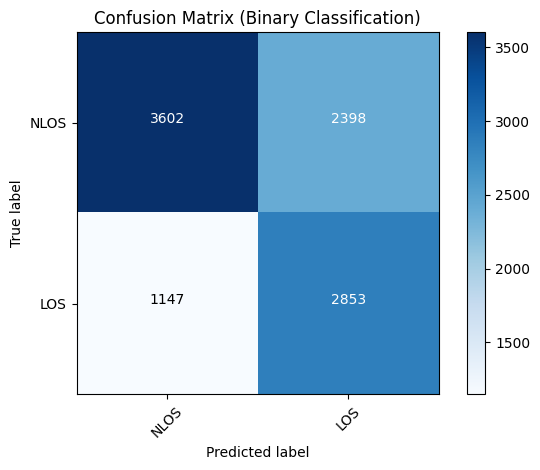

Confusion Matrix:
[[3602 2398]
 [1147 2853]]


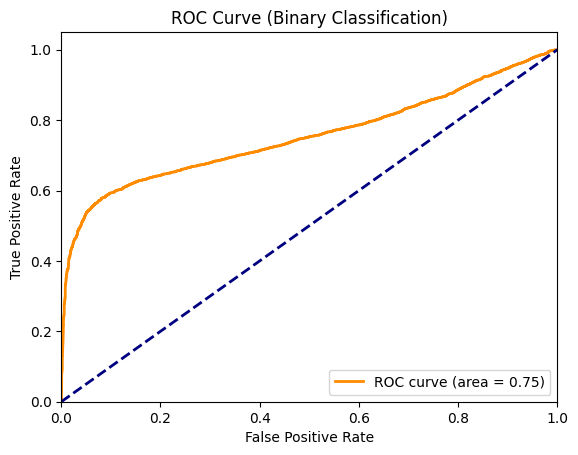

Accuracy: 0.6455
Precision: 0.5433
Recall (Sensitivity): 0.7133
Specificity: 0.6003
F1 Score: 0.6168
ROC AUC: 0.7534
Log Loss: 0.7285
Train Loss: 0.8466, Train Accuracy: 0.6507


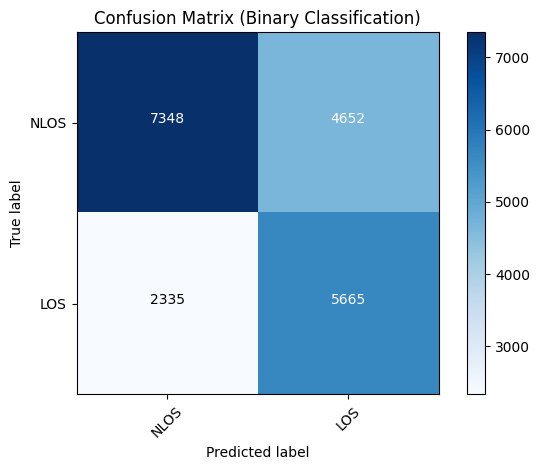

Confusion Matrix:
[[7348 4652]
 [2335 5665]]


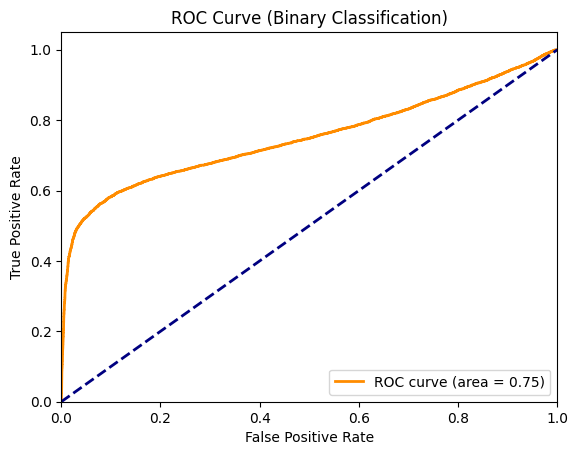

Accuracy: 0.6506
Precision: 0.5491
Recall (Sensitivity): 0.7081
Specificity: 0.6123
F1 Score: 0.6186
ROC AUC: 0.7502
Log Loss: 0.7268


In [14]:
import onnxruntime as ort  # ONNX Runtime for inference

# Load the best model
best_model_path = os.path.join(nlos_los_save_dir, "best_model.onnx")
if os.path.exists(best_model_path):
    print(f"Loading best model from {best_model_path}")
    # Use ONNX Runtime to load the ONNX model
    ort_session = ort.InferenceSession(best_model_path)
else:
    raise FileNotFoundError(f"Best model not found at {best_model_path}")

# Evaluate the model
test_loss = 0.0
test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
test_accuracy.reset_state()

y_true = []
y_pred = []
y_prob = []

for x_test, y_test in test_dataset:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy() if num_classes > 2 else (test_logits > 0.5).astype(int))

test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()

print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

# Convert probabilities to a flat list for binary classification
if num_classes == 2:
    y_prob = [p[0] for p in y_prob]

# Visualize metrics
if num_classes == 2:
    # Binary classification
    plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
    plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
    print_metrics(y_true, y_pred, y_prob)
else:
    # Multiclass classification
    classes = list(range(num_classes))  # Replace with actual class names if available
    plot_confusion_matrix_multiclass(y_true, y_pred, classes, title="Confusion Matrix (Multiclass Classification)")
    plot_roc_curve_multiclass(y_true, np.array(y_prob), classes, title="ROC Curve (Multiclass Classification)")
    print_metrics_multiclass(y_true, y_pred, y_prob, classes)
    
# training dataset evaluation metrics result
train_loss = 0.0
train_accuracy.reset_state()
y_true_train = []
y_pred_train = []
y_prob_train = []
for x_train, y_train in train_dataset:
    # Convert input to numpy for ONNX Runtime
    x_train_np = x_train.numpy()
    # Run inference using ONNX Runtime
    train_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_train_np})[0]
    train_loss += loss_fn(y_train, train_logits).numpy()
    train_accuracy.update_state(y_train, train_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true_train.extend(y_train.numpy())
    y_prob_train.extend(tf.nn.softmax(train_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(train_logits).numpy())
    y_pred_train.extend(tf.argmax(train_logits, axis=1).numpy() if num_classes > 2 else (train_logits > 0.5).astype(int))
train_loss /= len(train_dataset)
train_acc = train_accuracy.result().numpy()
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")
# Convert probabilities to a flat list for binary classification
if num_classes == 2:
    y_prob_train = [p[0] for p in y_prob_train]
# Visualize metrics
if num_classes == 2:
    # Binary classification
    plot_confusion_matrix(y_true_train, y_pred_train, title="Confusion Matrix (Binary Classification)")
    plot_roc_curve(y_true_train, y_prob_train, title="ROC Curve (Binary Classification)")
    print_metrics(y_true_train, y_pred_train, y_prob_train)

In [17]:
# n_downsamplings = 3
# n_blocks = 4

n_downsamplings = 1
n_blocks = 2
num_rx_tx = 4  # Number of receive and transmit antennas

input_shape = (192, 14, 4)
batch_size = 8

num_classes = np.unique(train_data_channel_labels).shape[0]
dim = 192
model = ResNetClassifier(
    input_shape=input_shape,
    num_classes=num_classes,
    num_rx_tx=num_rx_tx,  # Number of receive and transmit antennas
    dim=dim,
    n_downsamplings=n_downsamplings,
    n_blocks=n_blocks,
    norm='instance_norm'
    
)

model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (1, 192, 14, 4)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_50 (Conv2D)  │ (1, 96, 7, 384)   │     13,824 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_54 (ReLU)     │ (1, 96, 7, 384)   │          0 │ conv2d_50[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_51 (Conv2D)  │ (1, 96, 7, 384)   │    147,840 │ re_lu_54[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_55 (ReLU)     │ (1, 96, 7, 384)   │          0 │ conv2d_51[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_44 (Add)        │ (1, 96, 7, 384)   │          0 │ re_lu_54[0][0],   │
│                     │                   │            │ re_lu_55[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_52 (Conv2D)  │ (1, 96, 7, 384)   │    147,840 │ add_44[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_56 (ReLU)     │ (1, 96, 7, 384)   │          0 │ conv2d_52[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_45 (Add)        │ (1, 96, 7, 384)   │          0 │ add_44[0][0],     │
│                     │                   │            │ re_lu_56[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_53 (Conv2D)  │ (1, 96, 7, 384)   │    147,840 │ add_45[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_57 (ReLU)     │ (1, 96, 7, 384)   │          0 │ conv2d_53[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_46 (Add)        │ (1, 96, 7, 384)   │          0 │ add_45[0][0],     │
│                     │                   │            │ re_lu_57[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_54 (Conv2D)  │ (1, 96, 7, 384)   │    147,840 │ add_46[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_58 (ReLU)     │ (1, 96, 7, 384)   │          0 │ conv2d_54[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_47 (Add)        │ (1, 96, 7, 384)   │          0 │ add_46[0][0],     │
│                     │                   │            │ re_lu_58[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_4  │ (1, 192, 14, 192) │     73,728 │ add_47[0][0]      │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_59 (ReLU)     │ (1, 192, 14, 192) │          0 │ conv2d_transpose… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_55 (Conv2D)  │ (1, 192, 14, 4)   │        768 │ re_lu_59[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_60 (ReLU)     │ (1, 192, 14, 4)   │          0 │ conv2d_55[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute_2 (Permute) │ (1, 4, 14, 192)   │          0 │ re_lu_60[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (1, 192)          │          0 │ permute_2[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 686,186 (2.62 MB)

 Trainable params: 686,186 (2.62 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# TensorBoard writer
writer = tf.summary.create_file_writer(channel_log_dir)

# Define the loss function
loss_fn = tf.keras.losses.BinaryCrossentropy() if num_classes == 2 else tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
# print the loss function
# Define the optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002)

# Define metrics
train_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
val_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
# Training loop
epochs = 100  # Set the number of epochs
best_loss = float('inf')  # Track the best validation loss

train_dataset = train_channel_dataset
valid_dataset = test_channel_dataset
test_dataset = test_channel_dataset
@tf.function
def train_step(x_batch, y_batch):
    with tf.GradientTape() as tape:
        logits = model(x_batch, training=True)
        loss = loss_fn(y_batch, logits)
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    train_accuracy.update_state(y_batch, logits)
    return loss

@tf.function
def val_step(x_batch, y_batch):
    logits = model(x_batch, training=False)
    loss = loss_fn(y_batch, logits)
    val_accuracy.update_state(y_batch, logits)
    return loss


In [19]:
# Training loop
for epoch in range(epochs):
    print(f"Epoch {epoch + 1}/{epochs}")
    epoch_loss = 0.0
    train_accuracy.reset_state()

    for x_batch, y_batch in train_dataset:
        loss = train_step(x_batch, y_batch)
        
        epoch_loss += loss.numpy()
    
    epoch_loss /= len(train_dataset)
    train_acc = train_accuracy.result().numpy()

    # Log training metrics to TensorBoard
    with writer.as_default():
        tf.summary.scalar("training loss", epoch_loss, step=epoch)
        tf.summary.scalar("training accuracy", train_acc, step=epoch)

    print(f"Epoch {epoch + 1} Loss: {epoch_loss:.4f}, Accuracy: {train_acc:.4f}")

    # Validation loop
    val_loss = 0.0
    val_accuracy.reset_state()
    for x_val, y_val in valid_dataset:
        loss = val_step(x_val, y_val)
        val_loss += loss.numpy()

    val_loss /= len(valid_dataset)
    val_acc = val_accuracy.result().numpy()

    # Log validation metrics to TensorBoard
    with writer.as_default():
        tf.summary.scalar("validation loss", val_loss, step=epoch)
        tf.summary.scalar("validation accuracy", val_acc, step=epoch)

    print(f"Validation Loss: {val_loss:.4f}, Accuracy: {val_acc:.4f}")

    # Save the ONNX model at each epoch
    onnx_model_path = os.path.join(channel_save_dir, f"model_epoch_{epoch + 1:02d}.onnx")
    spec = (tf.TensorSpec((None,) + input_shape, tf.float32),)
    onnx_model, _ = tf2onnx.convert.from_keras(model, input_signature=spec, opset=11)
    with open(onnx_model_path, "wb") as f:
        f.write(onnx_model.SerializeToString())
    print(f"Model for epoch {epoch + 1} converted to ONNX and saved at {onnx_model_path}")

    # Save the best model based on validation loss
    
    if val_loss < best_loss or epoch == 0:
        best_loss = val_loss
        best_onnx_model_path = os.path.join(channel_save_dir, "best_model.onnx")
        with open(best_onnx_model_path, "wb") as f:
            f.write(onnx_model.SerializeToString())
        print("Best model saved in ONNX format based on validation loss")


Epoch 1/100
Epoch 1 Loss: 1.2693, Accuracy: 0.5954
Validation Loss: 2.4919, Accuracy: 0.1001


I0000 00:00:1743459188.658142  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743459188.659002  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743459188.660663  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743459188.905977  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743459188.990711  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743459188.990930  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743459188.992464  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Model for epoch 1 converted to ONNX and saved at saved_models_channel/20250331-214106/model_epoch_01.onnx
Best model saved in ONNX format based on validation loss
Epoch 2/100
Epoch 2 Loss: 1.2755, Accuracy: 0.5453
Validation Loss: 5.5835, Accuracy: 0.1695


I0000 00:00:1743459305.411428  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743459305.411998  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743459305.413522  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743459305.665415  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743459305.751678  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743459305.751919  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743459305.753276  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Model for epoch 2 converted to ONNX and saved at saved_models_channel/20250331-214106/model_epoch_02.onnx
Epoch 3/100
Epoch 3 Loss: 1.1082, Accuracy: 0.5809
Validation Loss: 9.3868, Accuracy: 0.1692


...

Model for epoch 98 converted to ONNX and saved at saved_models_channel/20250331-214106/model_epoch_98.onnx
Epoch 99/100
Epoch 99 Loss: 0.2792, Accuracy: 0.8992
Validation Loss: 3.9216, Accuracy: 0.2786


I0000 00:00:1743470669.079775  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743470669.080492  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743470669.082143  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743470669.320157  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743470669.411632  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743470669.411848  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743470669.413060  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Model for epoch 99 converted to ONNX and saved at saved_models_channel/20250331-214106/model_epoch_99.onnx
Epoch 100/100
Epoch 100 Loss: 0.2774, Accuracy: 0.9001
Validation Loss: 4.1735, Accuracy: 0.2788


I0000 00:00:1743470784.392926  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743470784.393528  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743470784.395011  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743470784.613165  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:86:00.0, compute capability: 7.0
I0000 00:00:1743470785.180796  805196 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1743470785.180993  805196 single_machine.cc:374] Starting new session
I0000 00:00:1743470785.182561  805196 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 wi

Model for epoch 100 converted to ONNX and saved at saved_models_channel/20250331-214106/model_epoch_100.onnx


Loading best model from saved_models_channel/20250331-214106/best_model.onnx
Test Loss: 2.4919, Test Accuracy: 0.1001


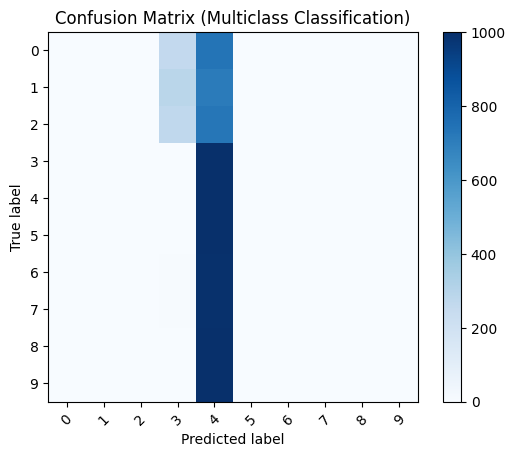

Confusion Matrix:
[[   0    0    3  261  736    0    0    0    0    0]
 [   0    0    1  289  710    0    0    0    0    0]
 [   0    0    1  269  730    0    0    0    0    0]
 [   0    0    0    0 1000    0    0    0    0    0]
 [   0    0    0    0 1000    0    0    0    0    0]
 [   0    0    0    0 1000    0    0    0    0    0]
 [   0    0    0    7  993    0    0    0    0    0]
 [   0    0    0    4  996    0    0    0    0    0]
 [   0    0    0    0 1000    0    0    0    0    0]
 [   0    0    0    0 1000    0    0    0    0    0]]


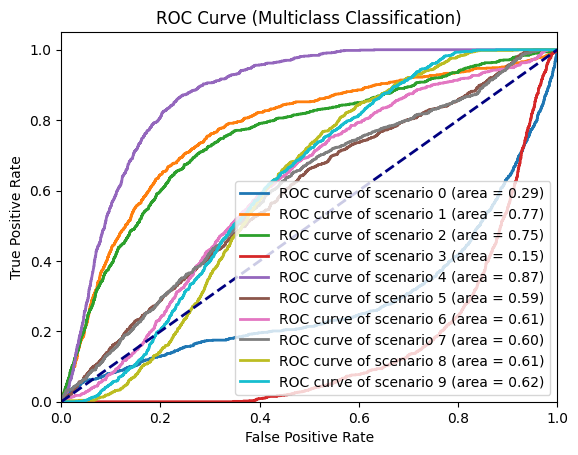

/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


Accuracy: 0.1001
Precision: 0.0309
Recall: 0.1001
F1 Score: 0.0199
ROC AUC: 0.5856
Log Loss: 2.3032
Train Loss: 2.4896, Train Accuracy: 0.1003


In [20]:
# Load the best model
best_model_path = os.path.join(channel_save_dir, "best_model.onnx")
if os.path.exists(best_model_path):
    print(f"Loading best model from {best_model_path}")
    # Use ONNX Runtime to load the ONNX model
    ort_session = ort.InferenceSession(best_model_path)
else:
    raise FileNotFoundError(f"Best model not found at {best_model_path}")

# Evaluate the model
test_loss = 0.0
test_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
test_accuracy.reset_state()

y_true = []
y_pred = []
y_prob = []

for x_test, y_test in test_dataset:
    # Convert input to numpy for ONNX Runtime
    x_test_np = x_test.numpy()
    # Run inference using ONNX Runtime
    test_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_test_np})[0]
    test_loss += loss_fn(y_test, test_logits).numpy()
    test_accuracy.update_state(y_test, test_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_test.numpy())
    y_prob.extend(tf.nn.softmax(test_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(test_logits).numpy())
    y_pred.extend(tf.argmax(test_logits, axis=1).numpy() if num_classes > 2 else (test_logits > 0.5).astype(int))

test_loss /= len(test_dataset)
test_acc = test_accuracy.result().numpy()

print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

# Convert probabilities to a flat list for binary classification
if num_classes == 2:
    y_prob = [p[0] for p in y_prob]

# Visualize metrics
if num_classes == 2:
    # Binary classification
    plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
    plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
    print_metrics(y_true, y_pred, y_prob)
else:
    # Multiclass classification
    classes = list(range(num_classes))  # Replace with actual class names if available
    plot_confusion_matrix_multiclass(y_true, y_pred, classes, title="Confusion Matrix (Multiclass Classification)")
    plot_roc_curve_multiclass(y_true, np.array(y_prob), classes, title="ROC Curve (Multiclass Classification)")
    print_metrics_multiclass(y_true, y_pred, y_prob)
    
# Training dataset evaluation values
train_loss = 0.0
train_accuracy.reset_state()
y_true = []
y_pred = []
y_prob = []

for x_train, y_train in train_dataset:
    # Convert input to numpy for ONNX Runtime
    x_train_np = x_train.numpy()
    # Run inference using ONNX Runtime
    train_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_train_np})[0]
    train_loss += loss_fn(y_train, train_logits).numpy()
    train_accuracy.update_state(y_train, train_logits)

    # Collect true labels, predicted labels, and probabilities
    y_true.extend(y_train.numpy())
    y_prob.extend(tf.nn.softmax(train_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(train_logits).numpy())
    y_pred.extend(tf.argmax(train_logits, axis=1).numpy() if num_classes > 2 else (train_logits > 0.5).astype(int))
train_loss /= len(train_dataset)
train_acc = train_accuracy.result().numpy()
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")
# Convert probabilities to a flat list for binary classification
if num_classes == 2:
    y_prob = [p[0] for p in y_prob]
# Visualize metrics
if num_classes == 2:
    # Binary classification
    plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix (Binary Classification)")
    plot_roc_curve(y_true, y_prob, title="ROC Curve (Binary Classification)")
    print_metrics(y_true, y_pred, y_prob)



Train Loss: 2.4896, Train Accuracy: 0.1003


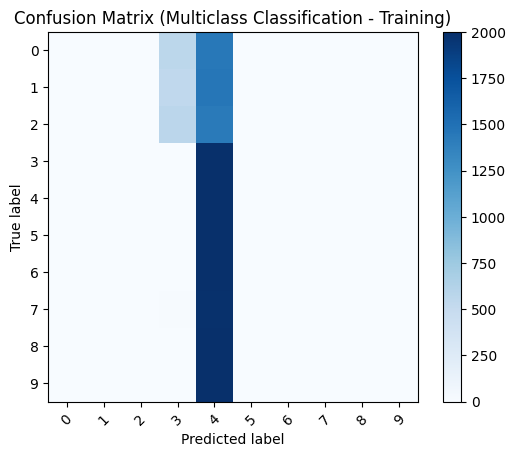

Confusion Matrix:
[[   0    0    1  556 1443    0    0    0    0    0]
 [   1    0    3  537 1459    0    0    0    0    0]
 [   0    0    7  567 1426    0    0    0    0    0]
 [   0    0    0    0 2000    0    0    0    0    0]
 [   0    0    0    0 2000    0    0    0    0    0]
 [   0    0    0    5 1995    0    0    0    0    0]
 [   0    0    0    3 1997    0    0    0    0    0]
 [   0    0    0    8 1992    0    0    0    0    0]
 [   0    0    0    0 2000    0    0    0    0    0]
 [   0    0    0    0 2000    0    0    0    0    0]]


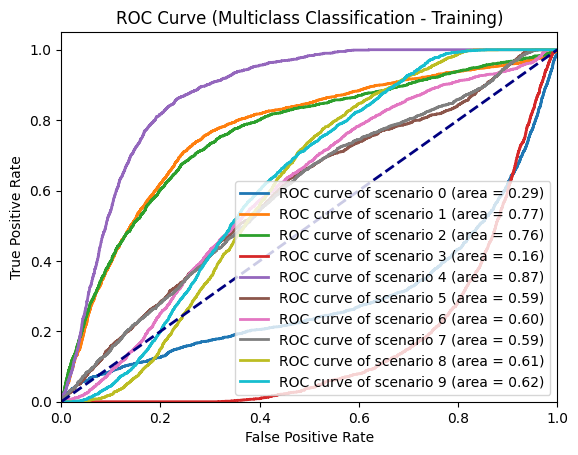

Accuracy: 0.1003
Precision: 0.0746
Recall: 0.1004
F1 Score: 0.0204
ROC AUC: 0.5876
Log Loss: 2.3029


/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/l2nguyen/miniconda3/envs/cnn/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [21]:
# Evaluate the model on the training dataset
train_loss = 0.0
train_accuracy = BinaryAccuracy() if num_classes == 2 else SparseCategoricalAccuracy()
train_accuracy.reset_state()

y_train_true = []
y_train_pred = []
y_train_prob = []

for x_train, y_train in train_dataset:
    # Convert input to numpy for ONNX Runtime
    x_train_np = x_train.numpy()
    # Run inference using ONNX Runtime
    train_logits = ort_session.run(None, {ort_session.get_inputs()[0].name: x_train_np})[0]
    train_loss += loss_fn(y_train, train_logits).numpy()
    train_accuracy.update_state(y_train, train_logits)

    # Collect true labels, predicted labels, and probabilities
    y_train_true.extend(y_train.numpy())
    y_train_prob.extend(tf.nn.softmax(train_logits).numpy() if num_classes > 2 else tf.nn.sigmoid(train_logits).numpy())
    y_train_pred.extend(tf.argmax(train_logits, axis=1).numpy() if num_classes > 2 else (train_logits > 0.5).astype(int))

train_loss /= len(train_dataset)
train_acc = train_accuracy.result().numpy()

print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}")

# Convert probabilities to a flat list for binary classification
if num_classes == 2:
    y_train_prob = [p[0] for p in y_train_prob]

# Visualize training metrics
if num_classes == 2:
    # Binary classification
    plot_confusion_matrix(y_train_true, y_train_pred, title="Confusion Matrix (Binary Classification - Training)")
    plot_roc_curve(y_train_true, y_train_prob, title="ROC Curve (Binary Classification - Training)")
    print_metrics(y_train_true, y_train_pred, y_train_prob)
else:
    # Multiclass classification
    plot_confusion_matrix_multiclass(y_train_true, y_train_pred, classes, title="Confusion Matrix (Multiclass Classification - Training)")
    plot_roc_curve_multiclass(y_train_true, np.array(y_train_prob), classes, title="ROC Curve (Multiclass Classification - Training)")
    print_metrics_multiclass(y_train_true, y_train_pred, y_train_prob)